# Gráficas de seguridad

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

RUTA_CSV = "/content/drive/MyDrive/Seguridad/percepcion_seguridad_alcaldias_cdmx.csv"

df = pd.read_csv(RUTA_CSV)
print(f"Filas: {len(df)}")
print(df.head())
print("\nColumnas:", list(df.columns))


Filtrar solo las alcaldías con estaciones de Ecobici

Mounted at /content/drive
Filas: 400
   anio    mes trimestre           region             alcaldia  \
0  2020  marzo        T1     Región Norte    Gustavo A. Madero   
1  2020  marzo        T1     Región Norte            Iztacalco   
2  2020  marzo        T1     Región Norte  Venustiano Carranza   
3  2020  marzo        T1  Región Poniente           Cuauhtémoc   
4  2020  marzo        T1       Región Sur        Benito Juárez   

   poblacion_18mas  seguro_abs  seguro_pct  inseguro_abs  inseguro_pct  
0           927734    189229.0   20.396903      734592.0     79.181317  
1           314361     49658.0   15.796489      263590.0     83.849460  
2           342088    127689.0   37.326360      213904.0     62.528940  
3           436195    135167.0   30.987746      298739.0     68.487488  
4           335399    170973.0   50.976002      164426.0     49.023998  

Columnas: ['anio', 'mes', 'trimestre', 'region', 'alcaldia', 'poblacion_18mas', 'seguro_abs', 'seguro_pct', 'inseguro_abs', 'in

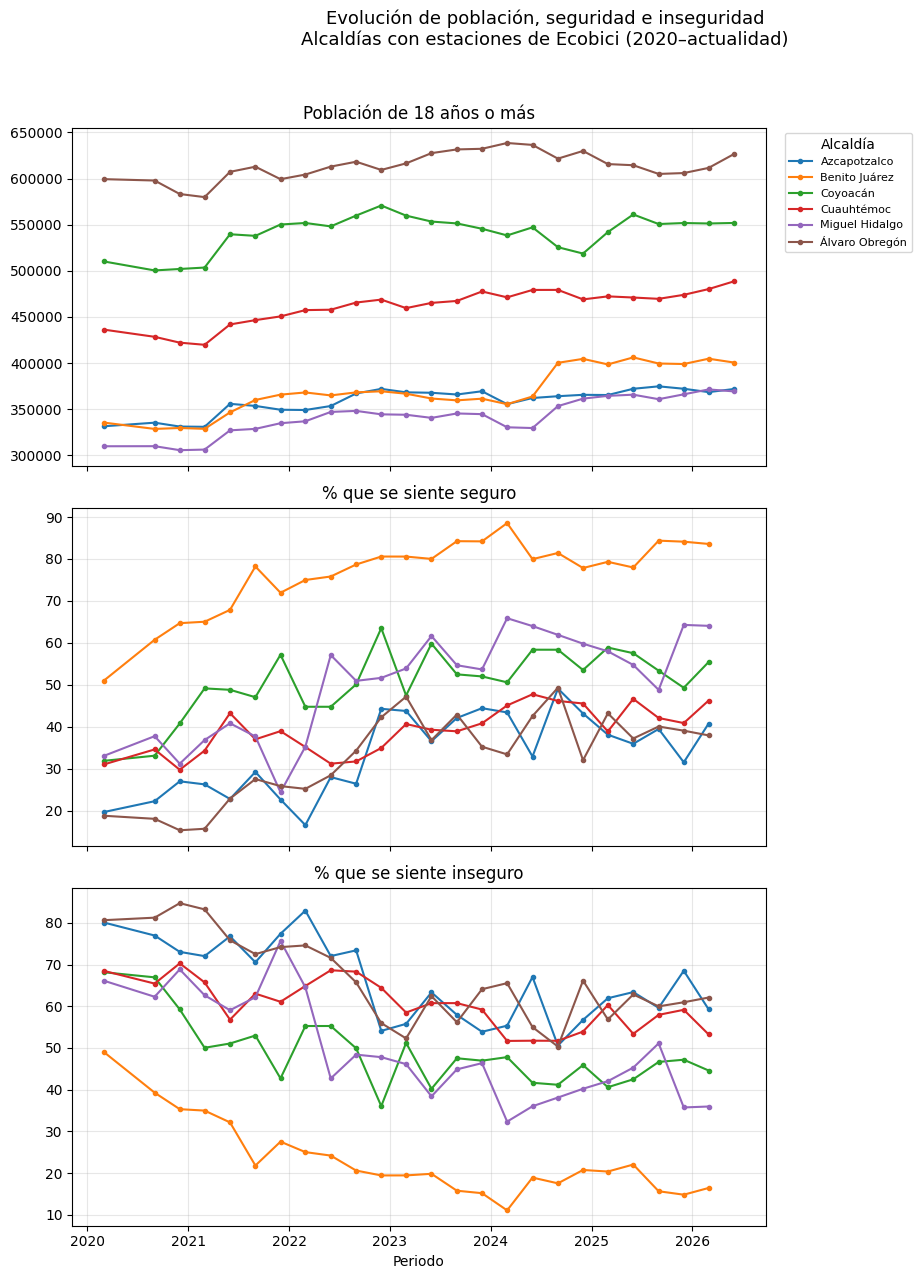

Figura guardada en: /content/drive/MyDrive/Seguridad/seguridad_vs_inseguridad_por_alcaldia.png


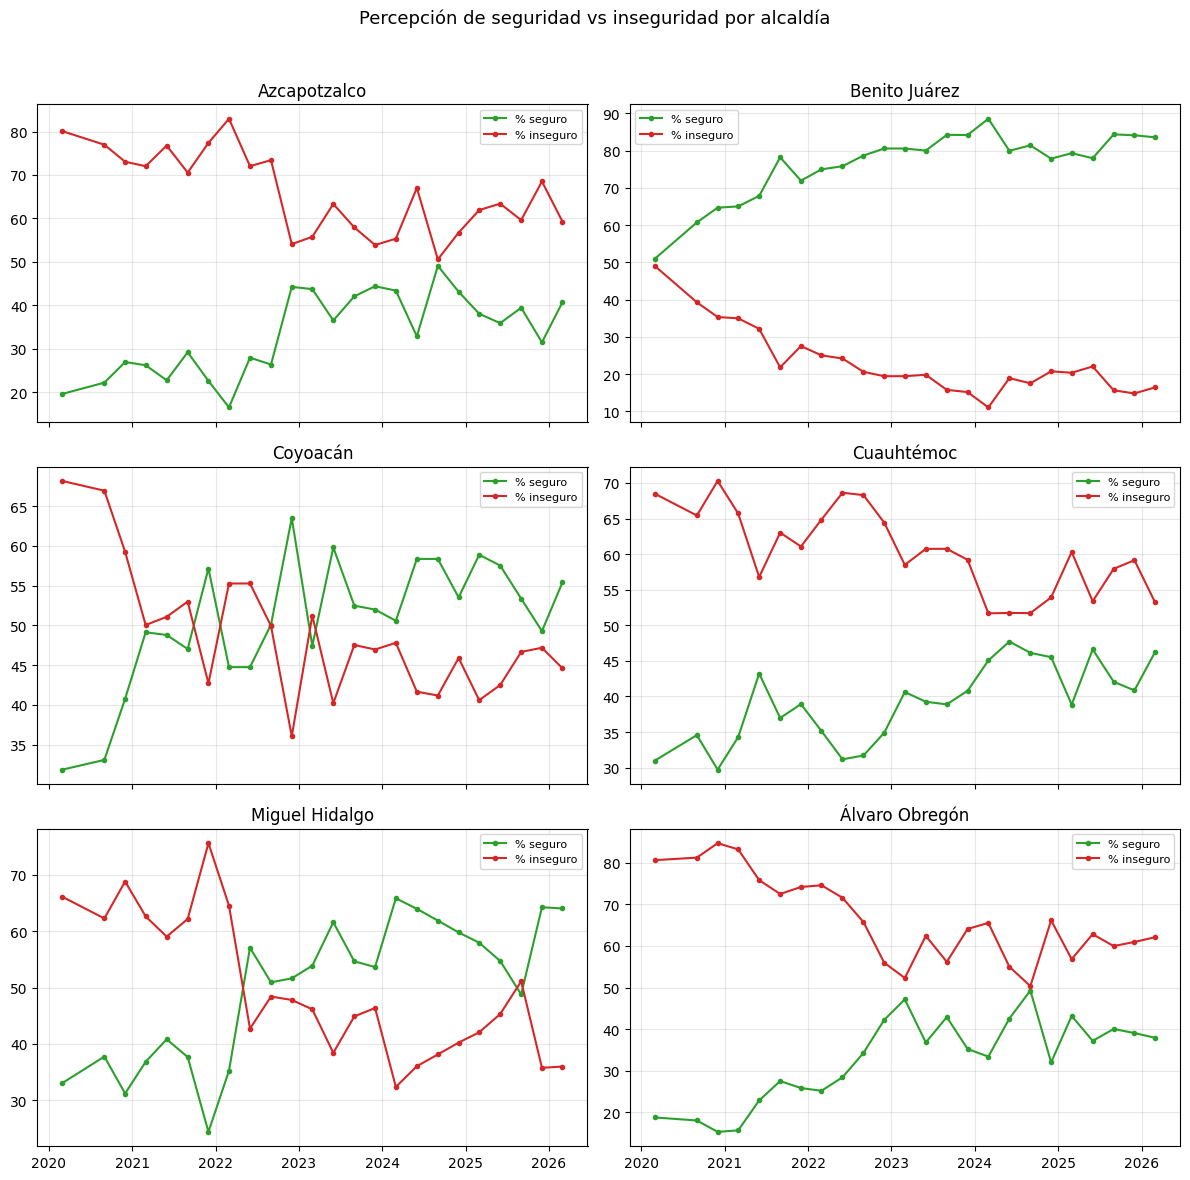

In [2]:
ALCALDIAS_ECOBICI = [
    "Cuauhtémoc",
    "Benito Juárez",
    "Miguel Hidalgo",
    "Coyoacán",
    "Azcapotzalco",
    "Álvaro Obregón",
]

df_filtrado = df[df["alcaldia"].isin(ALCALDIAS_ECOBICI)].copy()

faltantes = set(ALCALDIAS_ECOBICI) - set(df_filtrado["alcaldia"].unique())
if faltantes:
    print(f"⚠️  Estas alcaldías no se encontraron con ese nombre exacto en el CSV: {faltantes}")
    print("   Nombres disponibles en el CSV:", sorted(df["alcaldia"].unique()))

print(f"\nFilas después del filtro: {len(df_filtrado)}")


In [ ]:
# Mapeo mes -> número de mes, para poder ordenar cronológicamente
MESES = {
    "enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6,
    "julio": 7, "agosto": 8, "septiembre": 9, "octubre": 10,
    "noviembre": 11, "diciembre": 12,
}

df_filtrado["mes_num"] = df_filtrado["mes"].str.lower().map(MESES)
df_filtrado["periodo"] = pd.to_datetime(
    dict(year=df_filtrado["anio"], month=df_filtrado["mes_num"], day=1)
)
df_filtrado["periodo_label"] = (
    df_filtrado["anio"].astype(str) + "-" + df_filtrado["trimestre"]
)

df_filtrado = df_filtrado.sort_values(["alcaldia", "periodo"])

df_filtrado[["alcaldia", "anio", "trimestre", "periodo", "periodo_label"]].drop_duplicates().head(10)

Graficar: 3 paneles (Población, Seguridad, Inseguridad)
           una línea por alcaldía en cada panel


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(11, 13), sharex=True)

metricas = [
    ("poblacion_18mas", "Población de 18 años o más", axes[0]),
    ("seguro_pct", "% que se siente seguro", axes[1]),
    ("inseguro_pct", "% que se siente inseguro", axes[2]),
]

for alcaldia, grupo in df_filtrado.groupby("alcaldia"):
    grupo = grupo.sort_values("periodo")
    for columna, _, ax in metricas:
        ax.plot(grupo["periodo"], grupo[columna], marker="o", markersize=3, label=alcaldia)

for columna, titulo, ax in metricas:
    ax.set_title(titulo)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Periodo")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, title="Alcaldía")

fig.suptitle("Evolución de población, seguridad e inseguridad\n"
             "Alcaldías con estaciones de Ecobici (2020–actualidad)", fontsize=13)
fig.tight_layout(rect=[0, 0, 0.85, 0.96])

# Guardar la figura en Drive junto con los demás resultados
RUTA_FIGURA = "/content/drive/MyDrive/Seguridad/evolucion_seguridad_alcaldias_ecobici.png"
fig.savefig(RUTA_FIGURA, dpi=150, bbox_inches="tight")
print(f"Figura guardada en: {RUTA_FIGURA}")

plt.show()




Gráfica de cada alcaldía

In [ ]:

alcaldias_presentes = df_filtrado["alcaldia"].unique()
n = len(alcaldias_presentes)
cols = 2
rows = -(-n // cols)  # redondeo hacia arriba

fig2, axes2 = plt.subplots(rows, cols, figsize=(12, 4 * rows), sharex=True)
axes2 = axes2.flatten()

for i, alcaldia in enumerate(sorted(alcaldias_presentes)):
    ax = axes2[i]
    grupo = df_filtrado[df_filtrado["alcaldia"] == alcaldia].sort_values("periodo")
    ax.plot(grupo["periodo"], grupo["seguro_pct"], marker="o", markersize=3,
            label="% seguro", color="tab:green")
    ax.plot(grupo["periodo"], grupo["inseguro_pct"], marker="o", markersize=3,
            label="% inseguro", color="tab:red")
    ax.set_title(alcaldia)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

# Ocultar ejes sobrantes si el número de alcaldías es impar
for j in range(i + 1, len(axes2)):
    axes2[j].axis("off")

fig2.suptitle("Percepción de seguridad vs inseguridad por alcaldía", fontsize=13)
fig2.tight_layout(rect=[0, 0, 1, 0.96])

RUTA_FIGURA2 = "/content/drive/MyDrive/Seguridad/seguridad_vs_inseguridad_por_alcaldia.png"
fig2.savefig(RUTA_FIGURA2, dpi=150, bbox_inches="tight")
print(f"Figura guardada en: {RUTA_FIGURA2}")

plt.show()